## 0: Setup

In [13]:
import os
import numpy as np
import matplotlib.pyplot as plt
import cv2
from collections import deque

#configuring matplotlib plot styles
%matplotlib inline
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['image.cmap'] = 'gray'

print("NumPy Version:", np.__version__)
print("OpenCV Version (I/O only):", cv2.__version__)

NumPy Version: 1.26.4
OpenCV Version (I/O only): 5.0.0


---
## 1. Task 1: Generalized 2D and 3D Convolution Engines (20 Marks)

### 1.1 Task 1.1: 2D Spatial Convolution Function (`conv2d`) [10 Marks]

#### Mathematical Formulation:
Given an input image $I \in \mathbb{R}^{H_{in} \times W_{in}}$ and an odd-sized kernel $K \in \mathbb{R}^{k_h \times k_w}$ with stride $S$ and pad width $P$:

The spatial output dimensions strictly satisfy:
$$W_{out} = \left\lfloor \frac{W_{in} - k_w + 2P_w}{S} \right\rfloor + 1$$
$$H_{out} = \left\lfloor \frac{H_{in} - k_h + 2P_h}{S} \right\rfloor + 1$$

For each sliding window position $(i, j)$:
$$\text{Output}[i, j] = \sum_{u=0}^{k_h-1} \sum_{v=0}^{k_w-1} \text{PaddedImage}[i \cdot S + u, j \cdot S + v] \cdot K[u, v]$$

In [14]:
def conv2d(image: np.ndarray, kernel: np.ndarray, stride: int = 1, padding: str = 'same', pad_value: float = 0.0) -> np.ndarray:
    """
    Pure 2D spatial convolution (cross-correlation) from mathematical first principles.
    
    Parameters:
    -----------
    image : np.ndarray
        2D single-channel input image array of shape (H, W).
    kernel : np.ndarray
        2D filter kernel of shape (k_h, k_w) with odd spatial dimensions.
    stride : int, default=1
        Step size with which the kernel slides across the image.
    padding : str, default='same'
        Padding mode: 'same' (output size matches ceil(input / stride)) or 'valid' (no padding).
    pad_value : float, default=0.0
        Constant value used for boundary padding.
        
    Returns:
    --------
    output : np.ndarray
        2D convolved activation map of shape (H_out, W_out) as float64.
    """
    if image.ndim != 2:
        raise ValueError(f"Expected 2D image array of shape (H, W), got shape {image.shape}")
    if kernel.ndim != 2:
        raise ValueError(f"Expected 2D kernel array of shape (k_h, k_w), got shape {kernel.shape}")
    if stride < 1:
        raise ValueError(f"Stride must be a positive integer >= 1, got {stride}")
        
    H, W = image.shape
    k_h, k_w = kernel.shape
    
    # Assumes odd-sized kernels for 'same' padding logic
    if padding.lower() == 'same':
        pad_h = (k_h - 1) // 2
        pad_w = (k_w - 1) // 2
        padded_img = np.pad(
            image, 
            ((pad_h, pad_h), (pad_w, pad_w)), 
            mode='constant', 
            constant_values=pad_value
        )
    elif padding.lower() == 'valid':
        pad_h = 0
        pad_w = 0
        padded_img = image
    else:
        raise ValueError(f"Padding mode must be 'same' or 'valid', got '{padding}'")
        
    # Compute output spatial dimensions strictly satisfying the discrete spatial formula
    out_h = (padded_img.shape[0] - k_h) // stride + 1
    out_w = (padded_img.shape[1] - k_w) // stride + 1
    
    output = np.zeros((out_h, out_w), dtype=np.float64)
    
    # Sliding window dot product
    for i in range(out_h):
        for j in range(out_w):
            r_start = i * stride
            c_start = j * stride
            region = padded_img[r_start : r_start + k_h, c_start : c_start + k_w]
            output[i, j] = np.sum(region * kernel)
            
    return output

### 1.2 Task 1.2: 3D Multi-Channel Convolution Layer (`conv3d`) [10 Marks]

#### Mathematical Formulation:
Given a multi-channel image $I \in \mathbb{R}^{H_{in} \times W_{in} \times C}$ and a stack of $K$ kernels $\mathcal{K} = \{K^{(1)}, K^{(2)}, \dots, K^{(K)}\}$ where each kernel $K^{(k)} \in \mathbb{R}^{k_h \times k_w \times C}$:

For each filter index $k \in \{0, \dots, K-1\}$ and spatial position $(i, j)$:
$$\text{Output}[i, j, k] = \sum_{c=0}^{C-1} \sum_{u=0}^{k_h-1} \sum_{v=0}^{k_w-1} \text{PaddedImage}[i \cdot S + u, j \cdot S + v, c] \cdot K^{(k)}[u, v, c]$$

The output is stacked into an activation volume of shape $(H_{out}, W_{out}, K)$.

In [15]:
def conv3d(image: np.ndarray, kernel_stack: np.ndarray, stride: int = 1, padding: str = 'same', pad_value: float = 0.0) -> np.ndarray:
    """
    3D Multi-Channel Spatial Convolution Layer from mathematical first principles.
    
    Parameters:
    -----------
    image : np.ndarray
        3D multi-channel input image array of shape (H, W, C).
    kernel_stack : np.ndarray
        Bank of K filters of shape (K, k_h, k_w, C), or a single 3D kernel of shape (k_h, k_w, C).
    stride : int, default=1
        Step size with which the filters slide across spatial dimensions (H, W).
    padding : str, default='same'
        Padding mode: 'same' or 'valid'.
    pad_value : float, default=0.0
        Constant value used for boundary padding.
        
    Returns:
    --------
    output : np.ndarray
        3D activation volume of shape (H_out, W_out, K) as float64.
    """
    if image.ndim != 3:
        raise ValueError(f"Expected 3D input image of shape (H, W, C), got shape {image.shape}")
        
    # Standardize kernel_stack to shape (K, k_h, k_w, C)
    if kernel_stack.ndim == 3:
        kernel_stack = np.expand_dims(kernel_stack, axis=0)
    elif kernel_stack.ndim != 4:
        raise ValueError(f"Expected kernel_stack of shape (K, k_h, k_w, C) or (k_h, k_w, C), got {kernel_stack.shape}")
        
    K, k_h, k_w, k_c = kernel_stack.shape
    H, W, C = image.shape
    
    if C != k_c:
        raise ValueError(f"Channel mismatch: image has {C} channels but kernel stack has depth {k_c}")
    if stride < 1:
        raise ValueError(f"Stride must be a positive integer >= 1, got {stride}")
        
    # Spatial padding across height and width only
    if padding.lower() == 'same':
        pad_h = (k_h - 1) // 2
        pad_w = (k_w - 1) // 2
        padded_img = np.pad(
            image,
            ((pad_h, pad_h), (pad_w, pad_w), (0, 0)),
            mode='constant',
            constant_values=pad_value
        )
    elif padding.lower() == 'valid':
        padded_img = image
    else:
        raise ValueError(f"Padding mode must be 'same' or 'valid', got '{padding}'")
        
    out_h = (padded_img.shape[0] - k_h) // stride + 1
    out_w = (padded_img.shape[1] - k_w) // stride + 1
    
    output = np.zeros((out_h, out_w, K), dtype=np.float64)
    
    # Convolve each filter k across the spatial grid
    for k in range(K):
        current_kernel = kernel_stack[k]  # shape: (k_h, k_w, C)
        for i in range(out_h):
            for j in range(out_w):
                r_start = i * stride
                c_start = j * stride
                region = padded_img[r_start : r_start + k_h, c_start : c_start + k_w, :]
                output[i, j, k] = np.sum(region * current_kernel)
                
    return output

### 1.3 Task 1 Unit Testing & Verification Suite

We now thoroughly verify our `conv2d` and `conv3d` engines on:
1. **Identity Kernel Verification**: Output must exactly match input.
2. **Spatial Dimension Mathematical Formula**: Checking output shapes for various combinations of kernel size, stride, and padding mode.
3. **Hand-calculated Arithmetic**: Checking exact numerical dot products.
4. **Multi-Channel Stack Volume Test**: Checking output shapes and channel sums for 3D multi-channel inputs.

In [16]:
def run_task1_tests():
    print("=" * 60)
    print("RUNNING DETERMINISTIC TEST SUITE FOR TASK 1")
    print("=" * 60)
    
    # 1. Identity Kernel Test on conv2d
    test_img = np.array([
        [1.0, 2.0, 3.0, 4.0],
        [5.0, 6.0, 7.0, 8.0],
        [9.0, 10.0, 11.0, 12.0],
        [13.0, 14.0, 15.0, 16.0]
    ], dtype=np.float64)
    
    identity_k = np.array([
        [0.0, 0.0, 0.0],
        [0.0, 1.0, 0.0],
        [0.0, 0.0, 0.0]
    ], dtype=np.float64)
    
    ident_out = conv2d(test_img, identity_k, stride=1, padding='same')
    assert np.allclose(ident_out, test_img), "Identity test failed!"
    print("[PASS] conv2d Identity Kernel Test")
    
    # 2. Output Dimension Formula Verification
    # (H_in, W_in) = (7, 7), Kernel = (3, 3)
    img_7x7 = np.ones((7, 7))
    k_3x3 = np.ones((3, 3))
    
    # S=1, same -> 7x7
    out_s1_same = conv2d(img_7x7, k_3x3, stride=1, padding='same')
    assert out_s1_same.shape == (7, 7), f"Expected (7, 7), got {out_s1_same.shape}"
    
    # S=1, valid -> (7 - 3)/1 + 1 = 5x5
    out_s1_valid = conv2d(img_7x7, k_3x3, stride=1, padding='valid')
    assert out_s1_valid.shape == (5, 5), f"Expected (5, 5), got {out_s1_valid.shape}"
    
    # S=2, same -> floor((7 - 3 + 2)/2) + 1 = 4x4
    out_s2_same = conv2d(img_7x7, k_3x3, stride=2, padding='same')
    assert out_s2_same.shape == (4, 4), f"Expected (4, 4), got {out_s2_same.shape}"
    
    # S=2, valid -> floor((7 - 3 + 0)/2) + 1 = 3x3
    out_s2_valid = conv2d(img_7x7, k_3x3, stride=2, padding='valid')
    assert out_s2_valid.shape == (3, 3), f"Expected (3, 3), got {out_s2_valid.shape}"
    print("[PASS] conv2d Output Dimension Formula (same, valid, stride=1, stride=2)")
    
    # 3. Hand-Calculated Arithmetic Test
    box_kernel = np.ones((3, 3), dtype=np.float64) / 9.0
    hand_input = np.ones((3, 3), dtype=np.float64) * 9.0
    hand_valid = conv2d(hand_input, box_kernel, stride=1, padding='valid')
    assert hand_valid.shape == (1, 1) and np.isclose(hand_valid[0, 0], 9.0), "Hand-calculation failed!"
    print("[PASS] conv2d Hand-Calculated Box Kernel Sum Test")
    
    # 4. conv3d Multi-Channel Volume & Summation Test
    # Image shape: (6, 6, 3), Kernel stack: (4, 3, 3, 3) (4 filters of depth 3)
    img_3d = np.ones((6, 6, 3), dtype=np.float64)
    # Filter 0: all 1s across 3 channels -> sum at each valid window = 3 * 3 * 3 * 1 = 27
    # Filter 1: all 2s across 3 channels -> sum at each valid window = 27 * 2 = 54
    # Filter 2: all 0.5 across 3 channels -> sum = 13.5
    # Filter 3: all 0.1 across 3 channels -> sum = 2.7
    k_stack = np.zeros((4, 3, 3, 3), dtype=np.float64)
    k_stack[0, :, :, :] = 1.0
    k_stack[1, :, :, :] = 2.0
    k_stack[2, :, :, :] = 0.5
    k_stack[3, :, :, :] = 0.1
    
    out_3d_same = conv3d(img_3d, k_stack, stride=1, padding='same')
    assert out_3d_same.shape == (6, 6, 4), f"Expected shape (6, 6, 4), got {out_3d_same.shape}"
    
    out_3d_valid = conv3d(img_3d, k_stack, stride=1, padding='valid')
    assert out_3d_valid.shape == (4, 4, 4), f"Expected shape (4, 4, 4), got {out_3d_valid.shape}"
    assert np.allclose(out_3d_valid[:, :, 0], 27.0), "conv3d Filter 0 sum mismatch!"
    assert np.allclose(out_3d_valid[:, :, 1], 54.0), "conv3d Filter 1 sum mismatch!"
    assert np.allclose(out_3d_valid[:, :, 2], 13.5), "conv3d Filter 2 sum mismatch!"
    assert np.allclose(out_3d_valid[:, :, 3], 2.7), "conv3d Filter 3 sum mismatch!"
    print("[PASS] conv3d Shape, Multi-Channel Summation, and Volume Stacking Test")
    
    print("=" * 60)
    print("ALL TASK 1 UNIT TESTS PASSED SUCCESSFULLY! [PASSED]")
    print("=" * 60)

run_task1_tests()

RUNNING DETERMINISTIC TEST SUITE FOR TASK 1
[PASS] conv2d Identity Kernel Test
[PASS] conv2d Output Dimension Formula (same, valid, stride=1, stride=2)
[PASS] conv2d Hand-Calculated Box Kernel Sum Test
[PASS] conv3d Shape, Multi-Channel Summation, and Volume Stacking Test
ALL TASK 1 UNIT TESTS PASSED SUCCESSFULLY! [PASSED]


### 1.4 Real-Image Demonstration on Defect & Crack Samples

Let us now apply our custom `conv2d` and `conv3d` engines on real industrial inspection images from our dataset:
- **PCB Defect Image** (`data/pcb_defects/PCB_DATASET/images/Mouse_bite/` or `Spur/`)
- **Concrete Crack Image** (`data/concrete_cracks/Positive/`)

> **Note**: All arrays are normalized to $[0, 255]$ and cast to `np.uint8` for clean visual display without artifacts.

PCB sample exists: True (..\data\pcb_defects\PCB_DATASET\images\Mouse_bite\01_mouse_bite_01.jpg)
Crack sample exists: True (..\data\concrete_cracks\Positive\00001.jpg)
Saved Task 1 response figure to: ..\output_images\task1_conv2d_responses.png


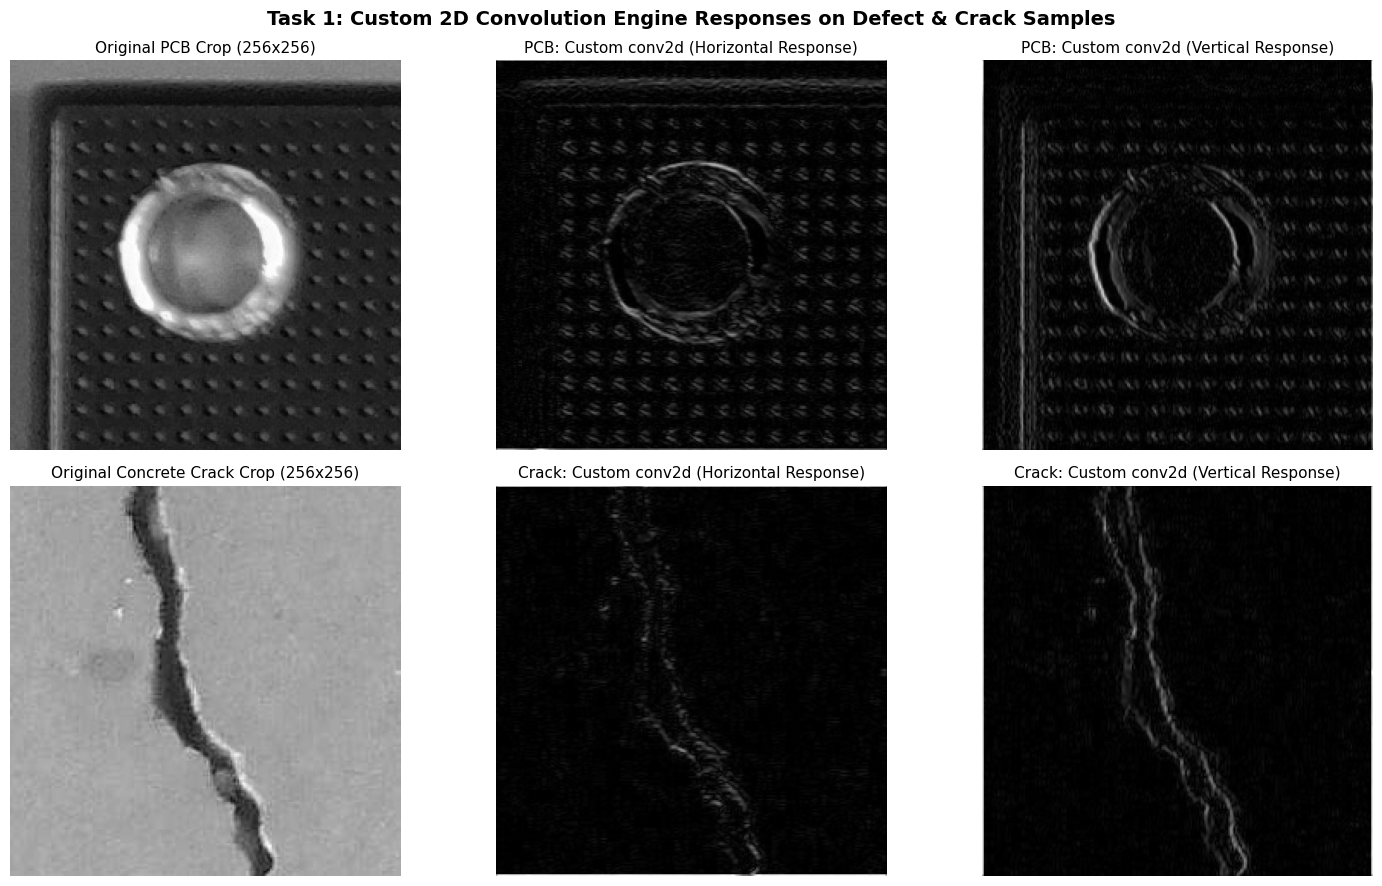

In [17]:
# Define paths to sample dataset images
pcb_sample_path = os.path.join('..', 'data', 'pcb_defects', 'PCB_DATASET', 'images', 'Mouse_bite', '01_mouse_bite_01.jpg')
if not os.path.exists(pcb_sample_path):
    # Fallback search if directory layout varies
    pcb_sample_path = os.path.join('..', 'data', 'pcb_defects', 'PCB_DATASET', 'images', 'Missing_hole', '01_missing_hole_01.jpg')

crack_sample_path = os.path.join('..', 'data', 'concrete_cracks', 'Positive', '00001.jpg')

print("PCB sample exists:", os.path.exists(pcb_sample_path), f"({pcb_sample_path})")
print("Crack sample exists:", os.path.exists(crack_sample_path), f"({crack_sample_path})")

# Load images using cv2 (permitted for I/O only)
pcb_bgr = cv2.imread(pcb_sample_path)
pcb_gray = cv2.cvtColor(pcb_bgr, cv2.COLOR_BGR2GRAY).astype(np.float64)

crack_bgr = cv2.imread(crack_sample_path)
crack_gray = cv2.cvtColor(crack_bgr, cv2.COLOR_BGR2GRAY).astype(np.float64)

# Resize/Crop if needed for rapid demonstration
pcb_crop = pcb_gray[:256, :256]
crack_crop = crack_gray[:256, :256]

# Define sample spatial filters (odd 3x3 kernels)
horizontal_edge_k = np.array([
    [-1, -2, -1],
    [ 0,  0,  0],
    [ 1,  2,  1]
], dtype=np.float64) / 8.0

vertical_edge_k = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
], dtype=np.float64) / 8.0

# Apply custom 2D convolution engine
pcb_h_edges = conv2d(pcb_crop, horizontal_edge_k, stride=1, padding='same')
pcb_v_edges = conv2d(pcb_crop, vertical_edge_k, stride=1, padding='same')
crack_h_edges = conv2d(crack_crop, horizontal_edge_k, stride=1, padding='same')
crack_v_edges = conv2d(crack_crop, vertical_edge_k, stride=1, padding='same')

# Normalize to [0, 255] uint8 for display
def to_display(arr):
    arr_abs = np.abs(arr)
    norm = (arr_abs - np.min(arr_abs)) / (np.max(arr_abs) - np.min(arr_abs) + 1e-8) * 255.0
    return norm.astype(np.uint8)

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

axes[0, 0].imshow(pcb_crop, cmap='gray')
axes[0, 0].set_title("Original PCB Crop (256x256)", fontsize=11)
axes[0, 0].axis('off')

axes[0, 1].imshow(to_display(pcb_h_edges), cmap='gray')
axes[0, 1].set_title("PCB: Custom conv2d (Horizontal Response)", fontsize=11)
axes[0, 1].axis('off')

axes[0, 2].imshow(to_display(pcb_v_edges), cmap='gray')
axes[0, 2].set_title("PCB: Custom conv2d (Vertical Response)", fontsize=11)
axes[0, 2].axis('off')

axes[1, 0].imshow(crack_crop, cmap='gray')
axes[1, 0].set_title("Original Concrete Crack Crop (256x256)", fontsize=11)
axes[1, 0].axis('off')

axes[1, 1].imshow(to_display(crack_h_edges), cmap='gray')
axes[1, 1].set_title("Crack: Custom conv2d (Horizontal Response)", fontsize=11)
axes[1, 1].axis('off')

axes[1, 2].imshow(to_display(crack_v_edges), cmap='gray')
axes[1, 2].set_title("Crack: Custom conv2d (Vertical Response)", fontsize=11)
axes[1, 2].axis('off')

plt.suptitle("Task 1: Custom 2D Convolution Engine Responses on Defect & Crack Samples", fontsize=14, fontweight='bold')
plt.tight_layout()

# Save figure to output_images
os.makedirs(os.path.join('..', 'output_images'), exist_ok=True)
output_fig_path = os.path.join('..', 'output_images', 'task1_conv2d_responses.png')
plt.savefig(output_fig_path, dpi=300, bbox_inches='tight')
print(f"Saved Task 1 response figure to: {output_fig_path}")
plt.show()

---
## 2. Task 2: Filtering, Contrast Sharpening & Subsampling (20 Marks)

In this section, we build fundamental spatial filtering operations from mathematical first principles:
1. **Isotropic 2D Gaussian Kernel**: Continuous 2D Gaussian density discretized on a spatial meshgrid and normalized.
2. **Unsharp Masking (High-Pass Detail Accentuation)**: Detail amplification using $F_{sharp} = F + \alpha \cdot (F - F * G_\sigma)$ with strict dynamic range clipping $[0, 255]$.
3. **Feature Subsampling via 2D Pooling**: Sliding-window downsampling supporting both `'max'` and `'average'` modes.

---
### 2.1 Theoretical Reflection: Analytical Derivative Derivation of Max Pooling
Consider a $2 \times 2$ max pooling block with input matrix:
$$\mathbf{X} = \begin{bmatrix} 8 & 7 \\ 12 & 9 \end{bmatrix}$$
The max pooling forward operation is defined as:
$$y = \max_{i,j} (X_{i,j}) = \max(8, 7, 12, 9) = 12 = X_{1, 0}$$
The analytical Jacobian/gradient matrix $\frac{\partial y}{\partial \mathbf{X}}$ is given by:
$$\frac{\partial y}{\partial \mathbf{X}} = \begin{bmatrix} 0 & 0 \\ 1 & 0 \end{bmatrix}$$

**Mathematical Explanation of Gradient Routing**:
The max pooling function is piecewise linear. For any input configuration where the elements are distinct (non-tied), the output $y$ is strictly determined by a single activation: the maximum element $X_{m, n}$. Consequently:
$$\frac{\partial y}{\partial X_{i, j}} = \begin{cases} 1 & \text{if } (i, j) = \arg\max_{k, l} X_{k, l} \\ 0 & \text{otherwise} \end{cases}$$
During backpropagation in deep neural networks and feature pyramids, error gradients $\frac{\partial \mathcal{L}}{\partial y}$ route exclusively through the winning neuron that achieved the maximum activation during the forward pass. All non-maximal features have a local partial derivative of $0$, meaning they receive zero gradient updates through that pooling window.

In [18]:
from filtering import generate_gaussian_kernel_2d, unsharp_mask, pool2d

# Display generated 5x5 isotropic Gaussian kernel
k_demo = generate_gaussian_kernel_2d(ksize=5, sigma=1.0)
print("5x5 Isotropic Gaussian Kernel (sigma=1.0):")
print(np.round(k_demo, 4))
print(f"Kernel Sum (Energy Conservation): {np.sum(k_demo):.6f}")

5x5 Isotropic Gaussian Kernel (sigma=1.0):
[[0.003  0.0133 0.0219 0.0133 0.003 ]
 [0.0133 0.0596 0.0983 0.0596 0.0133]
 [0.0219 0.0983 0.1621 0.0983 0.0219]
 [0.0133 0.0596 0.0983 0.0596 0.0133]
 [0.003  0.0133 0.0219 0.0133 0.003 ]]
Kernel Sum (Energy Conservation): 1.000000


In [19]:
def run_task2_tests():
    print("=" * 60)
    print("RUNNING DETERMINISTIC TEST SUITE FOR TASK 2")
    print("=" * 60)
    
    # 1. Gaussian Kernel Shape, Symmetry, and Normalization
    k7 = generate_gaussian_kernel_2d(7, 1.5)
    assert k7.shape == (7, 7), f"Expected (7, 7), got {k7.shape}"
    assert np.isclose(np.sum(k7), 1.0), f"Kernel sum {np.sum(k7)} != 1.0"
    assert np.allclose(k7, k7.T), "Gaussian kernel is not symmetric!"
    print("[PASS] Gaussian Kernel Synthesis & Normalization Test")
    
    # 2. Unsharp Mask Range Clipping
    test_contrast = np.array([
        [0.0, 255.0, 0.0],
        [255.0, 0.0, 255.0],
        [0.0, 255.0, 0.0]
    ], dtype=np.float64)
    sharp_clipped = unsharp_mask(test_contrast, sigma=1.0, alpha=5.0, ksize=3)
    assert np.all(sharp_clipped >= 0.0) and np.all(sharp_clipped <= 255.0), "Unsharp mask clipping failed!"
    print("[PASS] Unsharp Mask Dynamic Range Clipping [0, 255] Test")
    
    # 3. 2D Pooling & Theoretical Input Matrix Test
    theo_input = np.array([[8.0, 7.0], [12.0, 9.0]])
    max_p = pool2d(theo_input, pool_size=(2, 2), stride=2, mode='max')
    avg_p = pool2d(theo_input, pool_size=(2, 2), stride=2, mode='average')
    assert max_p.shape == (1, 1) and np.isclose(max_p[0, 0], 12.0), f"Max pool expected 12.0, got {max_p}"
    assert avg_p.shape == (1, 1) and np.isclose(avg_p[0, 0], 9.0), f"Avg pool expected 9.0, got {avg_p}"
    print("[PASS] 2D Pooling Analytical Derivation & Calculation Test")
    
    print("=" * 60)
    print("ALL TASK 2 UNIT TESTS PASSED SUCCESSFULLY! [PASSED]")
    print("=" * 60)

run_task2_tests()

RUNNING DETERMINISTIC TEST SUITE FOR TASK 2
[PASS] Gaussian Kernel Synthesis & Normalization Test
[PASS] Unsharp Mask Dynamic Range Clipping [0, 255] Test
[PASS] 2D Pooling Analytical Derivation & Calculation Test
ALL TASK 2 UNIT TESTS PASSED SUCCESSFULLY! [PASSED]


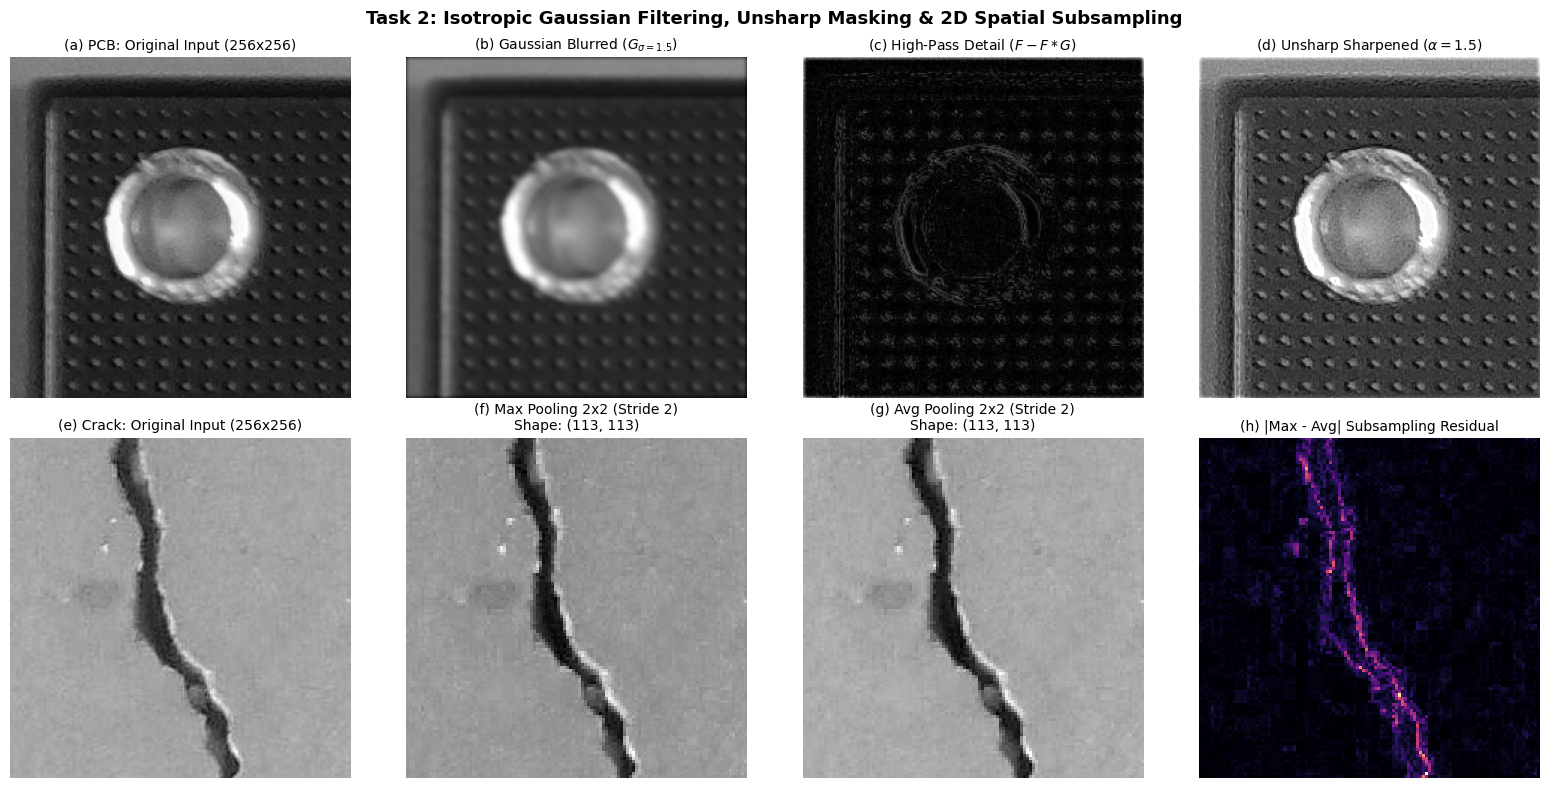

In [20]:
# Visual demonstration of Task 2 on PCB and Crack samples
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

# PCB Unsharp Masking
pcb_sharp = unsharp_mask(pcb_crop, sigma=1.5, alpha=1.5)
pcb_k = generate_gaussian_kernel_2d(9, 1.5)
pcb_blur = conv2d(pcb_crop, pcb_k, stride=1, padding='same')
pcb_detail = pcb_crop - pcb_blur

axes[0, 0].imshow(pcb_crop, cmap='gray')
axes[0, 0].set_title("(a) PCB: Original Input (256x256)", fontsize=10)
axes[0, 0].axis('off')

axes[0, 1].imshow(pcb_blur, cmap='gray')
axes[0, 1].set_title(r"(b) Gaussian Blurred ($G_{\sigma=1.5}$)", fontsize=10)
axes[0, 1].axis('off')

axes[0, 2].imshow(to_display(pcb_detail), cmap='gray')
axes[0, 2].set_title(r"(c) High-Pass Detail ($F - F*G$)", fontsize=10)
axes[0, 2].axis('off')

axes[0, 3].imshow(pcb_sharp, cmap='gray')
axes[0, 3].set_title(r"(d) Unsharp Sharpened ($\alpha=1.5$)", fontsize=10)
axes[0, 3].axis('off')

# Crack 2D Pooling
crack_max_pool = pool2d(crack_crop, pool_size=(2, 2), stride=2, mode='max')
crack_avg_pool = pool2d(crack_crop, pool_size=(2, 2), stride=2, mode='average')
diff_pool = np.abs(crack_max_pool - crack_avg_pool)

axes[1, 0].imshow(crack_crop, cmap='gray')
axes[1, 0].set_title("(e) Crack: Original Input (256x256)", fontsize=10)
axes[1, 0].axis('off')

axes[1, 1].imshow(crack_max_pool, cmap='gray')
axes[1, 1].set_title(f"(f) Max Pooling 2x2 (Stride 2)\nShape: {crack_max_pool.shape}", fontsize=10)
axes[1, 1].axis('off')

axes[1, 2].imshow(crack_avg_pool, cmap='gray')
axes[1, 2].set_title(f"(g) Avg Pooling 2x2 (Stride 2)\nShape: {crack_avg_pool.shape}", fontsize=10)
axes[1, 2].axis('off')

axes[1, 3].imshow(to_display(diff_pool), cmap='magma')
axes[1, 3].set_title("(h) |Max - Avg| Subsampling Residual", fontsize=10)
axes[1, 3].axis('off')

plt.suptitle("Task 2: Isotropic Gaussian Filtering, Unsharp Masking & 2D Spatial Subsampling", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join('..', 'output_images', 'task2_unsharp_and_pooling.png'), dpi=300, bbox_inches='tight')
plt.show()

---
## 3. Task 3: First-Principles Canny Edge Detection Pipeline (30 Marks)

The Canny edge detector is the benchmark optimal edge detection algorithm satisfying three criteria:
1. **Low Error Rate**: Marking real edges while suppressing spurious noise.
2. **Localization**: Minimizing distance between detected edge pixels and true structural centers.
3. **Single Response**: Thinning multi-pixel responses to 1-pixel wide ridges.

### Pipeline Architecture:
- **Stage 1: Pre-smoothing & Normalized Sobel Gradients**:
  $$S_x = \frac{1}{8} \begin{bmatrix} -1 & 0 & 1 \\ -2 & 0 & 2 \\ -1 & 0 & 1 \end{bmatrix}, \quad S_y = \frac{1}{8} \begin{bmatrix} 1 & 2 & 1 \\ 0 & 0 & 0 \\ -1 & -2 & -1 \end{bmatrix}$$
  $$M = \sqrt{S_x^2 + S_y^2}, \quad \theta = \text{atan2}(S_y, S_x) \in [0, 180^\circ)$$
- **Stage 2: 4-Sector Non-Maximum Suppression (NMS)**:
  Continuous gradient orientations are quantized into 4 canonical sectors:
  - Sector 0 ($0^\circ \pm 22.5^\circ$): Compare with horizontal neighbors $(i, j-1)$ and $(i, j+1)$.
  - Sector 1 ($45^\circ \pm 22.5^\circ$): Compare with diagonal neighbors $(i-1, j+1)$ and $(i+1, j-1)$.
  - Sector 2 ($90^\circ \pm 22.5^\circ$): Compare with vertical neighbors $(i-1, j)$ and $(i+1, j)$.
  - Sector 3 ($135^\circ \pm 22.5^\circ$): Compare with anti-diagonal neighbors $(i-1, j-1)$ and $(i+1, j+1)$.
  Pixel is retained if and only if $M[i, j] > q$ and $M[i, j] > r$ (strict inequality); borders zeroed out.
- **Stage 3: Double Thresholding & 8-Connected Hysteresis Tracking**:
  Pixels categorized into Strong ($M \ge T_{high}$), Weak ($T_{low} \le M < T_{high}$), and Non-edge ($M < T_{low}$).
  Weak pixels are retained iff connected directly or transitively to a strong edge via 8-connectivity (using BFS with `collections.deque`).

In [21]:
from canny import sobel_gradients, non_max_suppression, hysteresis_tracking, canny_edge_detector

def run_task3_tests():
    print("=" * 60)
    print("RUNNING DETERMINISTIC TEST SUITE FOR TASK 3")
    print("=" * 60)
    
    # 1. Sobel Step Edge Direction & Magnitude Test
    step_img = np.zeros((15, 15), dtype=np.float64)
    step_img[:, 7:] = 100.0
    _, sx, sy, mag, theta = sobel_gradients(step_img, sigma=1.0, pre_smooth=False)
    assert np.all(sx[2:13, 7] == 50.0), "Sobel X step edge response mismatch!"
    assert np.all(sy[2:13, :] == 0.0), "Sobel Y should be zero on purely vertical edge!"
    print("[PASS] Sobel Operator Step Edge Response Test")
    
    # 2. Strict NMS Suppression & Border Zeroing Test
    test_mag = np.array([
        [0, 10, 50, 10, 0],
        [0, 15, 60, 15, 0],
        [0, 12, 55, 12, 0]
    ], dtype=np.float64)
    test_theta = np.zeros_like(test_mag)  # Sector 0
    nms_out = non_max_suppression(test_mag, test_theta)
    assert nms_out[1, 2] == 60.0, f"Expected 60.0, got {nms_out[1, 2]}"
    assert nms_out[1, 1] == 0.0 and nms_out[1, 3] == 0.0, "NMS failed to suppress neighbors!"
    assert nms_out[0, 2] == 0.0 and nms_out[2, 2] == 0.0, "Borders must be 0!"
    print("[PASS] 4-Sector Strict NMS & Border Zeroing Test")
    
    # 3. 8-Connected Hysteresis BFS Tracking Test
    test_nms = np.array([
        [0,   0,   0,   0,  0],
        [0, 100,  40,   0,  0],  # (1,1) strong, (1,2) weak connected
        [0,   0,   0,   0,  0],
        [0,   0,   0,  40,  0],  # (3,3) weak isolated
        [0,   0,   0,   0,  0]
    ], dtype=np.float64)
    h_out = hysteresis_tracking(test_nms, low_thresh=30.0, high_thresh=80.0)
    assert h_out[1, 1] == 255, "Strong edge missing!"
    assert h_out[1, 2] == 255, "Connected weak edge not promoted!"
    assert h_out[3, 3] == 0, "Isolated weak edge should be suppressed!"
    print("[PASS] 8-Connected BFS Hysteresis Edge Linking Test")
    
    print("=" * 60)
    print("ALL TASK 3 UNIT TESTS PASSED SUCCESSFULLY! [PASSED]")
    print("=" * 60)

run_task3_tests()

RUNNING DETERMINISTIC TEST SUITE FOR TASK 3
[PASS] Sobel Operator Step Edge Response Test
[PASS] 4-Sector Strict NMS & Border Zeroing Test
[PASS] 8-Connected BFS Hysteresis Edge Linking Test
ALL TASK 3 UNIT TESTS PASSED SUCCESSFULLY! [PASSED]


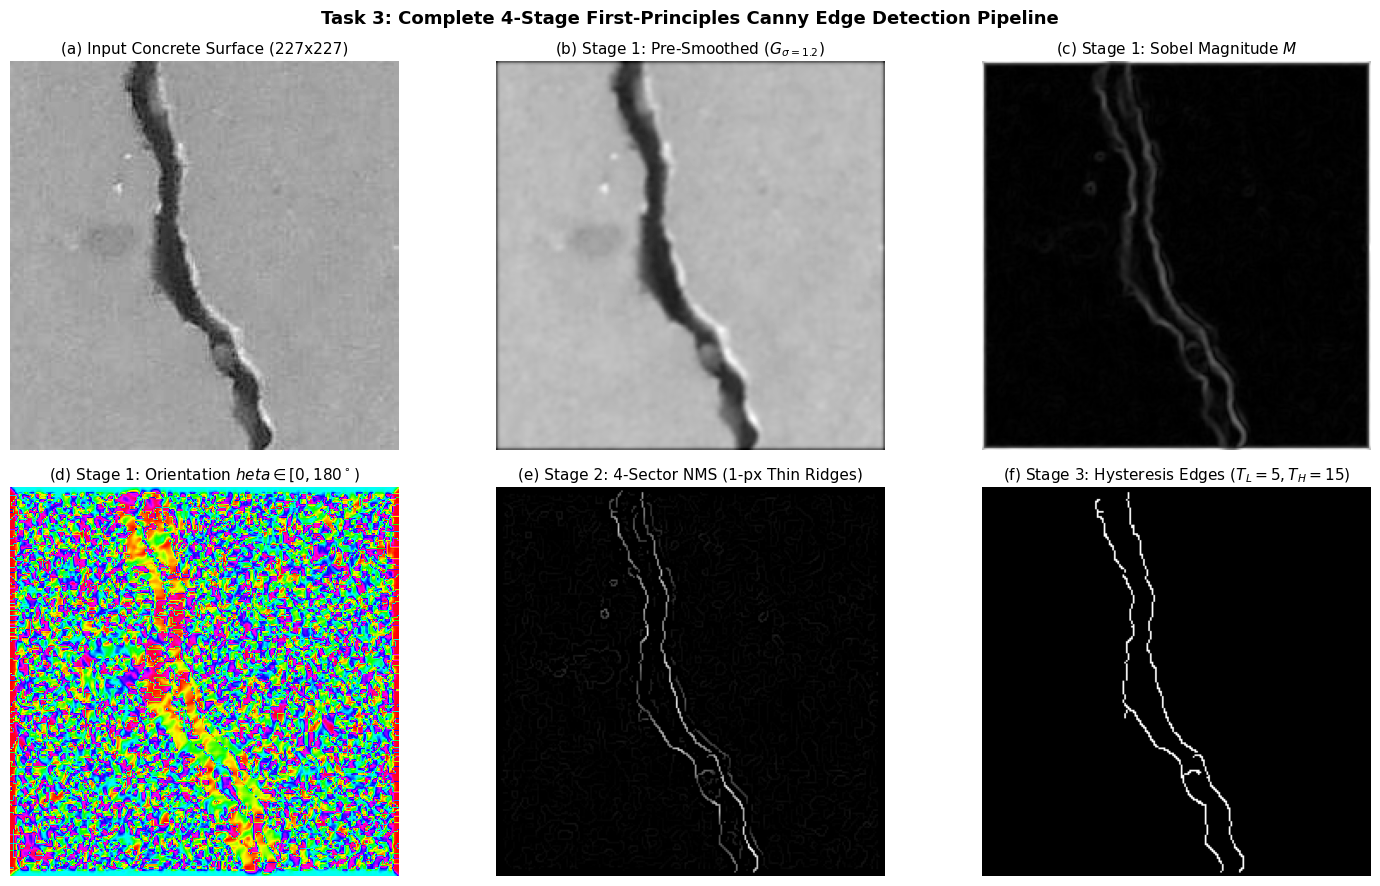

In [22]:
# Visual demonstration of complete 4-stage Canny Edge Detection Pipeline
crack_full_path = os.path.join('..', 'data', 'concrete_cracks', 'Positive', '00001.jpg')
crack_bgr = cv2.imread(crack_full_path)
crack_gray = cv2.cvtColor(crack_bgr, cv2.COLOR_BGR2GRAY).astype(np.float64)

results = canny_edge_detector(crack_gray, sigma=1.2, low_thresh=5.0, high_thresh=15.0)

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

axes[0, 0].imshow(crack_gray, cmap='gray')
axes[0, 0].set_title("(a) Input Concrete Surface (227x227)", fontsize=11)
axes[0, 0].axis('off')

axes[0, 1].imshow(results['smoothed'], cmap='gray')
axes[0, 1].set_title(r"(b) Stage 1: Pre-Smoothed ($G_{\sigma=1.2}$)", fontsize=11)
axes[0, 1].axis('off')

axes[0, 2].imshow(to_display(results['magnitude']), cmap='gray')
axes[0, 2].set_title(r"(c) Stage 1: Sobel Magnitude $M$", fontsize=11)
axes[0, 2].axis('off')

axes[1, 0].imshow(results['orientation'], cmap='hsv')
axes[1, 0].set_title(r"(d) Stage 1: Orientation $	heta \in [0, 180^\circ)$", fontsize=11)
axes[1, 0].axis('off')

axes[1, 1].imshow(to_display(results['nms']), cmap='gray')
axes[1, 1].set_title("(e) Stage 2: 4-Sector NMS (1-px Thin Ridges)", fontsize=11)
axes[1, 1].axis('off')

axes[1, 2].imshow(results['edges'], cmap='gray')
axes[1, 2].set_title(r"(f) Stage 3: Hysteresis Edges ($T_L=5, T_H=15$)", fontsize=11)
axes[1, 2].axis('off')

plt.suptitle("Task 3: Complete 4-Stage First-Principles Canny Edge Detection Pipeline", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join('..', 'output_images', 'task3_canny_stages.png'), dpi=300, bbox_inches='tight')
plt.show()

---
## 4. Task 4: Step-by-Step Visual Ablation Study (15 Marks)

Ablation experiments isolate individual components of the vision pipeline to rigorously quantify their impact:
- **Ablation 1 (Impact of Noise & Smoothing)**: Synthesize additive Gaussian noise $\mathcal{N}(0, \sigma_n^2)$ with $\sigma_n \in \{10, 25, 40\}$ to show how derivatives amplify high frequencies and why Gaussian pre-smoothing is mandatory.
- **Ablation 2 (Impact of NMS)**: Contrast thick, blurred gradient bands against 1-pixel wide thin ridges to demonstrate spatial localization.
- **Ablation 3 (Impact of Hysteresis vs. Single Thresholding)**: Contrast single global thresholding (noisy or broken edges) against dual-threshold hysteresis linking (continuous micro-cracks with clean backgrounds).

Generating Task 4.1 Ablation 1 (Noise & Smoothing) figure...
Saved: C:\Users\Ibrahim\Desktop\Parhayi\UNI\Semester 7\Comp Vision\Assignment01\output_images\task4_ablation1_noise_smoothing.png


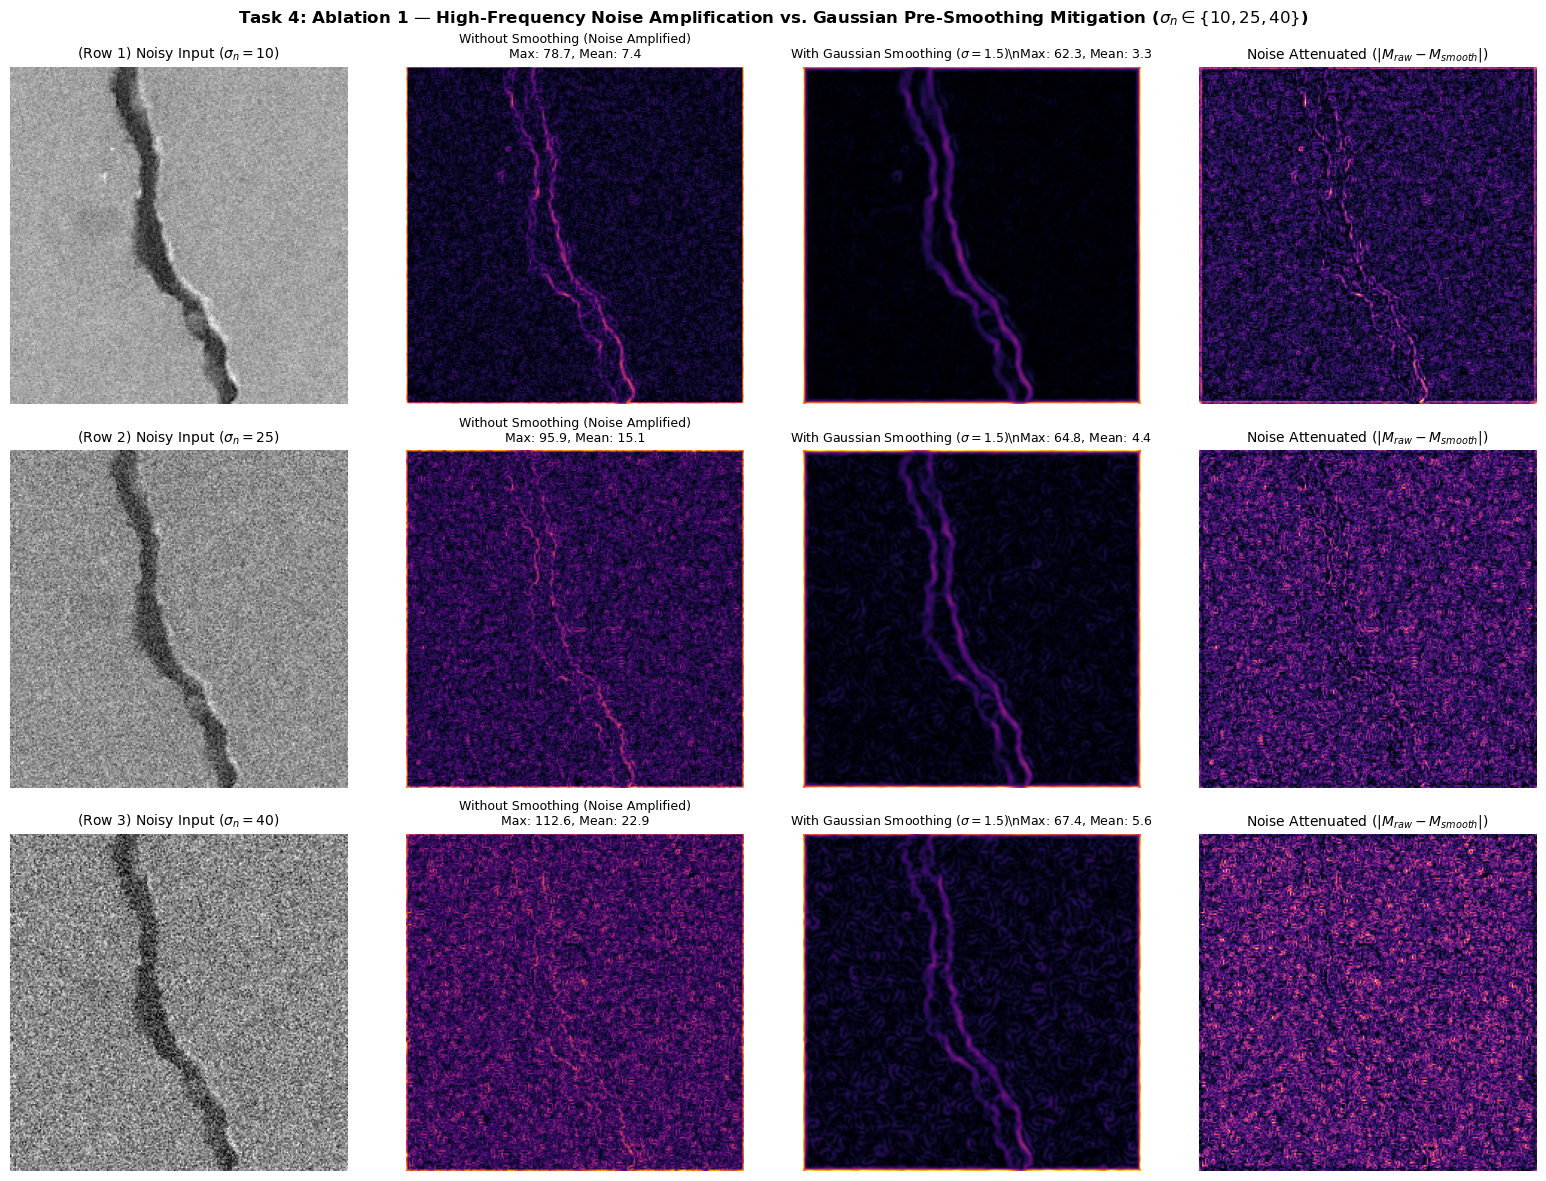

Generating Task 4.2 Ablation 2 (Pre/Post NMS) figure...
Saved: C:\Users\Ibrahim\Desktop\Parhayi\UNI\Semester 7\Comp Vision\Assignment01\output_images\task4_ablation2_pre_post_nms.png


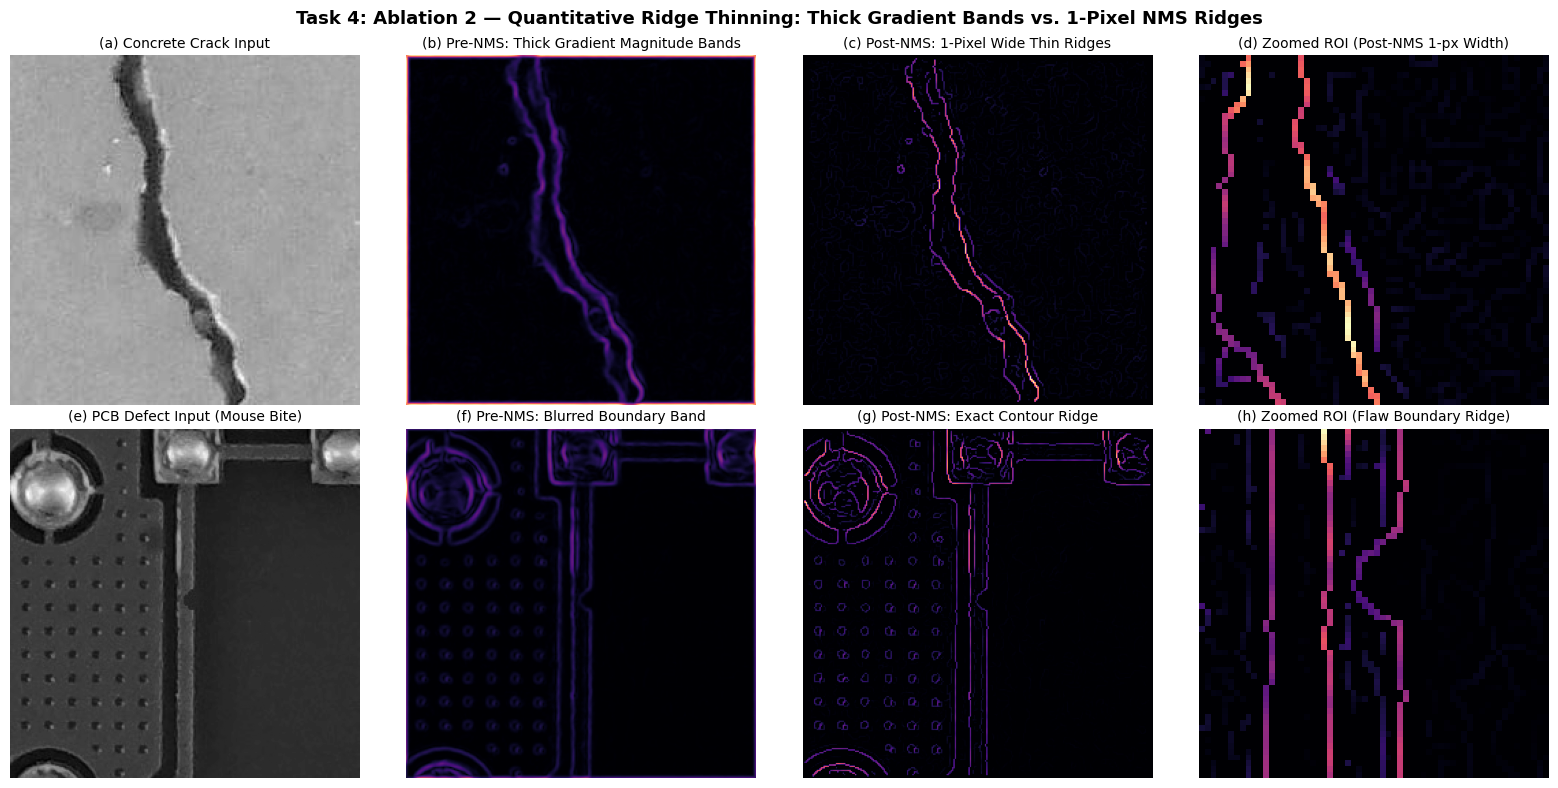

Generating Task 4.3 Ablation 3 (Hysteresis vs. Single) figure...
Saved: C:\Users\Ibrahim\Desktop\Parhayi\UNI\Semester 7\Comp Vision\Assignment01\output_images\task4_ablation3_hysteresis_vs_single.png


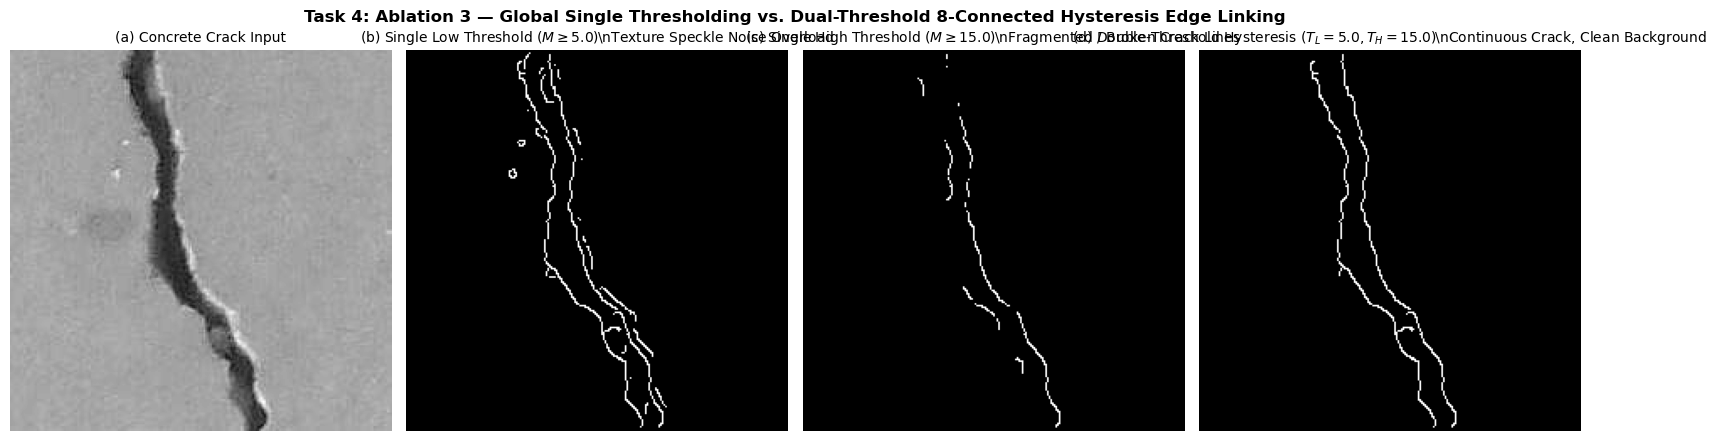

In [23]:
from experiments import (
    run_ablation1_noise_smoothing,
    run_ablation2_pre_post_nms,
    run_ablation3_hysteresis_vs_single
)

pcb_full_path = os.path.join('..', 'data', 'pcb_defects', 'PCB_DATASET', 'images', 'Mouse_bite', '01_mouse_bite_01.jpg')
pcb_bgr = cv2.imread(pcb_full_path)
pcb_gray_full = cv2.cvtColor(pcb_bgr, cv2.COLOR_BGR2GRAY).astype(np.float64)
pcb_sample = pcb_gray_full[810:1066, 1400:1656]

# Execute and display Task 4 Ablations
run_ablation1_noise_smoothing(crack_gray)
run_ablation2_pre_post_nms(crack_gray, pcb_sample)
run_ablation3_hysteresis_vs_single(crack_gray)

---
## 5. Task 5: Scale-Space, Sensitivity & Failure Case Analysis (15 Marks)

### 5.1 Witkin's Scale-Space Causality Theorem
Scale-space representation satisfies the linear heat/diffusion equation:
$$\frac{\partial I(x, y; t)}{\partial t} = \nabla^2 I(x, y; t), \quad t = \frac{1}{2}\sigma^2$$
Witkin's scale-space causality states that as scale $\sigma$ increases (progressive diffusion), existing zero-crossings and gradient ridges may drift, merge, or extinguish monotonically, but **new edge features can never emerge out of nowhere** (no edge genesis).

### 5.2 Parameter Sensitivity & Optimal Regimes
We examine a $3 \times 3$ grid varying $(T_{high}, T_{low})$ across our defect datasets to identify the operational sweet spot balancing sensitivity and specificity.

### 5.3 Failure Case Investigation
We identify and document two realistic failure scenarios:
1. **Strong Illumination Gradients / Shadow Contours**: Edge detectors mistake non-structural lighting variations for material defects.
2. **Severe Surface Texture Clutter**: High-frequency aggregate speckle triggers false alarm cascades obscuring subtle micro-cracks.

Generating Task 5.1 Scale-Space Causality figure...
Saved: C:\Users\Ibrahim\Desktop\Parhayi\UNI\Semester 7\Comp Vision\Assignment01\output_images\task5_scalespace_causality.png


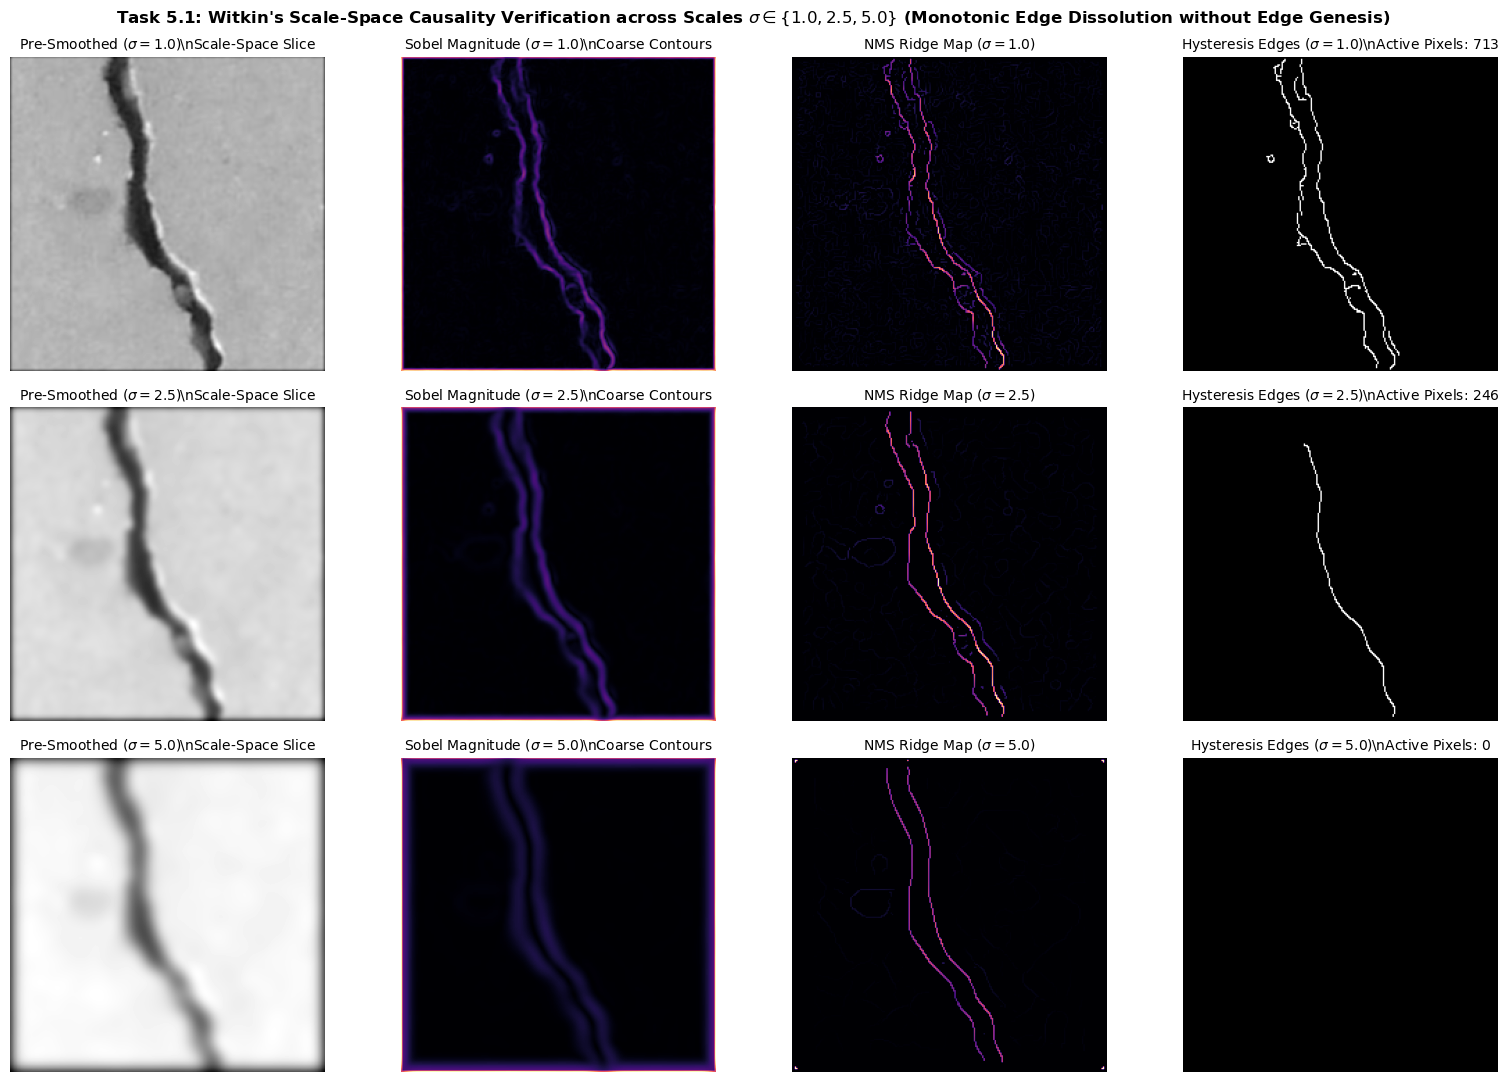

Generating Task 5.2 Parameter Sensitivity Grid figure...
Saved: C:\Users\Ibrahim\Desktop\Parhayi\UNI\Semester 7\Comp Vision\Assignment01\output_images\task5_parameter_sensitivity_grid.png


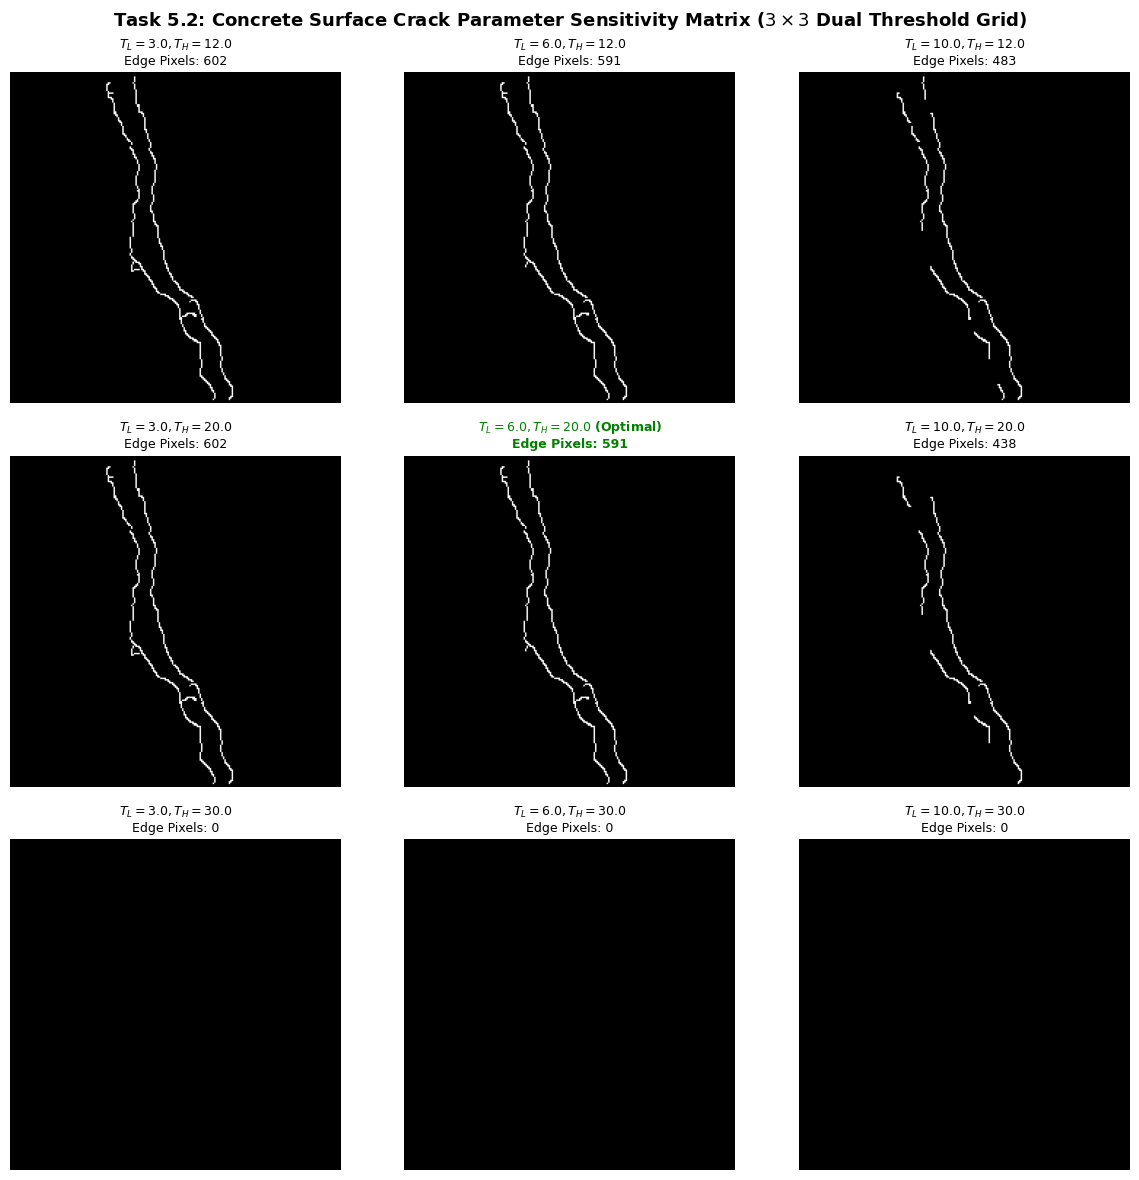

Generating Task 5.3 Failure Case Investigation figure...
Saved: C:\Users\Ibrahim\Desktop\Parhayi\UNI\Semester 7\Comp Vision\Assignment01\output_images\task5_failure_cases.png


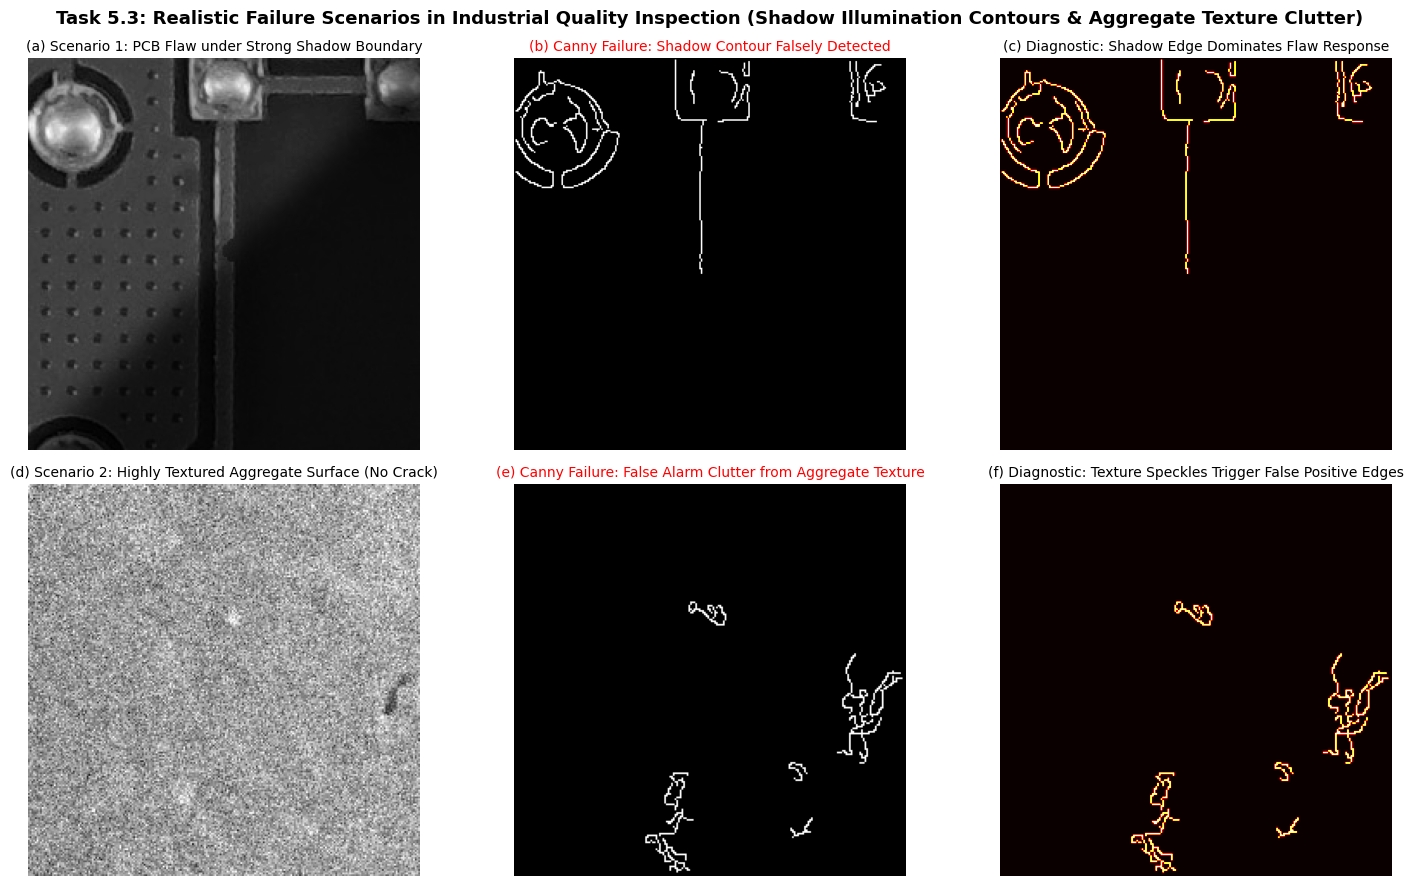

In [24]:
from experiments import (
    run_scalespace_causality,
    run_parameter_sensitivity_grid,
    run_failure_case_analysis,
    load_dataset_samples
)

pcb_s, crack_s, neg_s = load_dataset_samples()

# Execute and display Task 5 Experiments
run_scalespace_causality(crack_s)
run_parameter_sensitivity_grid(crack_s, pcb_s)
run_failure_case_analysis(pcb_s, crack_s, neg_s)